# Association Rules: A Simple Recommender with the Apriori Algorithm

Final project for the *Introduction to Data Science* course.

**Group 4**
- Femi Novia Lina
- Cesilia Natasya Nainggolan
- Alya Fitri Nurhaliza

**Dataset:** [Grocery Products Purchase](https://www.kaggle.com/alexmiles/grocery-products-purchase-data) (Kaggle, AlexMiles).
It is the well-known *Groceries* dataset from the R package [`arules`](https://search.r-project.org/CRAN/refmans/arules/html/Groceries.html):
one month of point-of-sale data from a local grocery store, 9,835 baskets, 169 product categories.
Original reference: Hahsler, Hornik & Reutterer (2006), *Implications of probabilistic data modeling for mining association rules*, Springer.

**Goal:** given the items a customer has already put in the basket, suggest what they are likely to add next.

**Roadmap:** load data -> explore -> mine frequent itemsets (Apriori) -> turn them into rules -> build a recommender -> evaluate it honestly against a popularity baseline.

> Runs in about a minute on a laptop. Run it from the `notebooks/` folder.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify
import networkx as nx
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# one consistent look for every chart
BLUE, ORANGE, AQUA, VIOLET, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#8a8a85"
sns.set_theme(style="whitegrid", context="notebook", rc={
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e6e3", "figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
SEQ = sns.light_palette(BLUE, as_cmap=True)   # one hue, light -> dark, for magnitude
RNG = np.random.default_rng(42)

## 1. Load the data

In [2]:
raw = pd.read_csv("../data/grocery-products-purchase.csv")
print("shape:", raw.shape)
raw.head()

shape: (9835, 32)


,Product 1,Product 2,Product 3,Product 4,Product 5,Product 6,Product 7,Product 8,Product 9,Product 10,...,Product 23,Product 24,Product 25,Product 26,Product 27,Product 28,Product 29,Product 30,Product 31,Product 32
0,citrus fruit,semi-finished bread,margarine,ready soups,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,tropical fruit,yogurt,coffee,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,whole milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pip fruit,yogurt,cream cheese,meat spreads,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,other vegetables,whole milk,condensed milk,long life bakery product,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**How to read this table.** One row is one basket. The 32 columns are *slots*, not product types: slot 1 holds the first item, slot 2 the second, and so on. Most cells are empty (`NaN`) because most baskets are small. That is just the wide format, not missing data, so nothing needs imputing.

## 2. Understand and prepare the data

In [3]:
cells = raw.size
print(f"empty cells: {raw.isna().sum().sum():,} of {cells:,} ({raw.isna().sum().sum()/cells:.1%}) -> expected, wide format")
print(f"identical baskets: {raw.duplicated().sum():,}")

empty cells: 271,353 of 314,720 (86.2%) -> expected, wide format
identical baskets: 2,824


**About the 2,824 "duplicates".** These are baskets that happen to contain exactly the same items (typically one-item baskets like `whole milk`). They are real, separate purchases, so we **keep them**. Dropping them would understate how popular those items are.

Next: lowercase and trim the text (*case folding*), and turn each row into a list of items.

In [4]:
baskets = [[str(x).strip().lower() for x in row if isinstance(x, str)] for row in raw.values]
sizes = pd.Series([len(b) for b in baskets], name="items per basket")
item_counts = Counter(i for b in baskets for i in b)
items = (pd.DataFrame(item_counts.items(), columns=["item", "count"])
           .sort_values("count", ascending=False).reset_index(drop=True))
items["support"] = items["count"] / len(baskets)

print(f"{len(baskets):,} baskets, {len(items)} distinct items, {sizes.sum():,} item purchases")
print(f"average basket: {sizes.mean():.2f} items, median: {sizes.median():.0f}, max: {sizes.max()}")

9,835 baskets, 169 distinct items, 43,367 item purchases
average basket: 4.41 items, median: 3, max: 32


### 2.1 How big are the baskets?

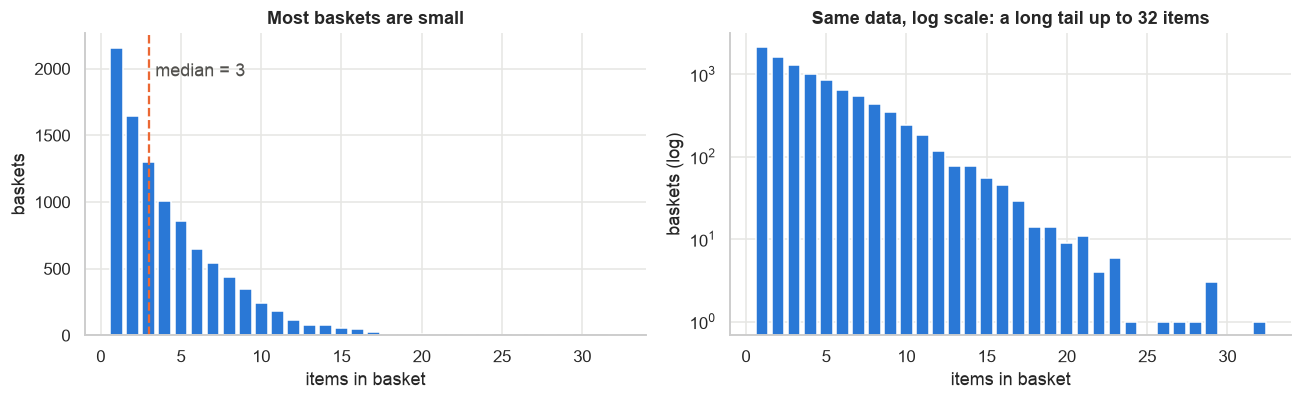

22.0% of baskets have a single item. They cannot produce any rule, since a rule needs at least two items.


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
vc = sizes.value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color=BLUE, width=0.8)
ax[0].set(title="Most baskets are small", xlabel="items in basket", ylabel="baskets")
ax[0].axvline(sizes.median(), color=ORANGE, ls="--"); ax[0].text(sizes.median()+0.4, vc.max()*0.9, f"median = {sizes.median():.0f}", color="#52514e")
ax[1].bar(vc.index, vc.values, color=BLUE, width=0.8); ax[1].set_yscale("log")
ax[1].set(title="Same data, log scale: a long tail up to 32 items", xlabel="items in basket", ylabel="baskets (log)")
plt.tight_layout(); plt.show()
print(f"{(sizes==1).mean():.1%} of baskets have a single item. They cannot produce any rule, since a rule needs at least two items.")

**Takeaway.** Around one basket in five has a single item, and the median is 3. Rules can only be learned from baskets with 2+ items, so the usable signal is smaller than 9,835 rows suggests.

### 2.2 What do people buy most?

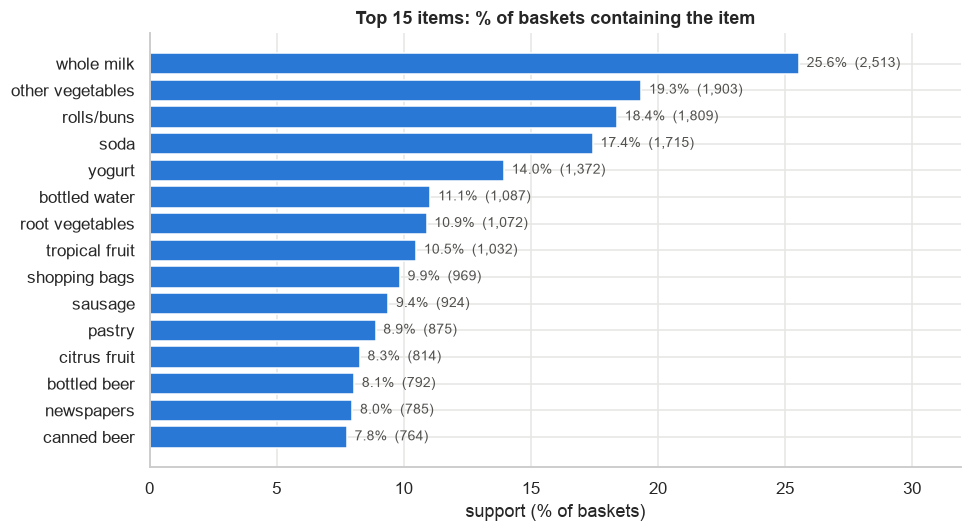

In [6]:
top = items.head(15)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["item"][::-1], top["support"][::-1]*100, color=BLUE)
for y, (s, c) in enumerate(zip(top["support"][::-1]*100, top["count"][::-1])):
    ax.text(s+0.3, y, f"{s:.1f}%  ({c:,})", va="center", fontsize=9, color="#52514e")
ax.set(title="Top 15 items: % of baskets containing the item", xlabel="support (% of baskets)")
ax.set_xlim(0, top["support"].max()*100*1.25)
plt.tight_layout(); plt.show()

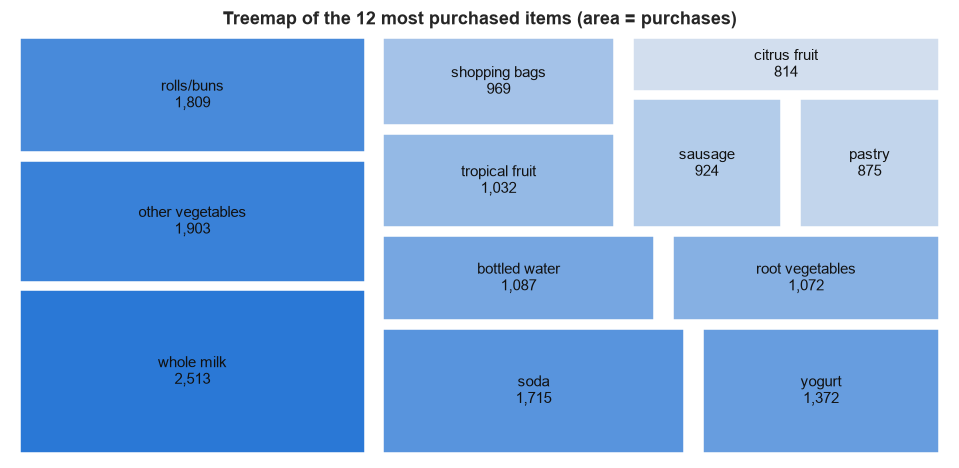

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
t = items.head(12)
squarify.plot(t["count"], label=[f"{a}\n{b:,}" for a, b in zip(t["item"], t["count"])],
              color=sns.light_palette(BLUE, n_colors=14)[2:][::-1], text_kwargs={"fontsize": 10, "color": "#111"},
              ax=ax, pad=True)
ax.set_title("Treemap of the 12 most purchased items (area = purchases)"); ax.axis("off"); plt.show()

### 2.3 The long tail

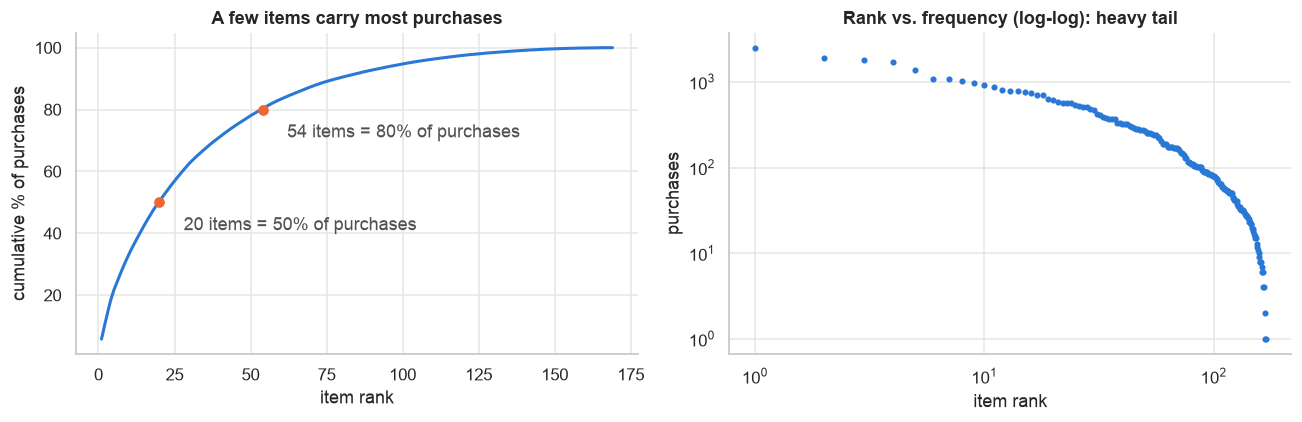

Items that appear in fewer than 1% of baskets: 81 of 169


In [8]:
cum = items["count"].cumsum() / items["count"].sum()
rank = np.arange(1, len(items)+1)
n50, n80 = int((cum < .5).sum()+1), int((cum < .8).sum()+1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(rank, cum*100, color=BLUE, lw=2)
for n, c in [(n50, 50), (n80, 80)]:
    ax[0].plot([n], [c], "o", color=ORANGE); ax[0].annotate(f"{n} items = {c}% of purchases", (n, c), (n+8, c-9), color="#52514e")
ax[0].set(title="A few items carry most purchases", xlabel="item rank", ylabel="cumulative % of purchases")
ax[1].loglog(rank, items["count"], ".", color=BLUE)
ax[1].set(title="Rank vs. frequency (log-log): heavy tail", xlabel="item rank", ylabel="purchases")
plt.tight_layout(); plt.show()
print(f"Items that appear in fewer than 1% of baskets: {(items['support']<0.01).sum()} of {len(items)}")

**Takeaway.** Just 20 of the 169 items (12%) account for half of all purchases, and 54 items (32%) for 80%. At a `min_support` of 1%, most of the 169 items cannot appear in any rule at all. That is a core limit of Apriori: it favours popular items and says little about rare ones.

### 2.4 Which items go together? (a first look, before any algorithm)

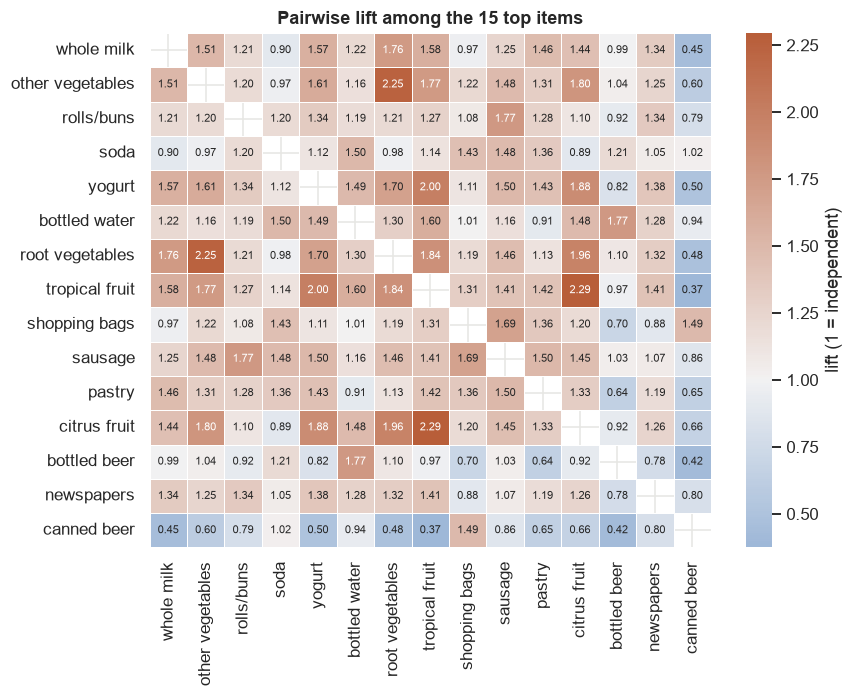

In [9]:
topn = items["item"].head(15).tolist()
idx = {n: i for i, n in enumerate(topn)}
co = np.zeros((15, 15))
for b in baskets:
    s = [i for i in set(b) if i in idx]
    for a, c in combinations(s, 2):
        co[idx[a], idx[c]] += 1; co[idx[c], idx[a]] += 1
sup = items.set_index("item").loc[topn, "support"].values
lift_m = (co/len(baskets)) / np.outer(sup, sup)
np.fill_diagonal(lift_m, np.nan)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(pd.DataFrame(lift_m, topn, topn), cmap=sns.diverging_palette(250, 25, center="light", as_cmap=True),
            center=1, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=.5, cbar_kws={"label": "lift (1 = independent)"}, ax=ax)
ax.set_title("Pairwise lift among the 15 top items"); plt.tight_layout(); plt.show()

**How to read it.** Lift above 1 (blue) means two items appear together *more* than chance would predict. Below 1 (orange) means they are bought together *less* often than chance. Fresh produce (`root vegetables`, `other vegetables`, `tropical fruit`, `citrus fruit`) and `yogurt` all pull each other up, with lifts around 1.7 to 2.3. `canned beer` is the opposite: it sits well below 1 against nearly every fresh item. This matrix is the idea behind everything that follows.

## 3. Mining frequent itemsets with Apriori

**Idea.** An itemset is *frequent* if its **support** (the share of baskets containing it) is at least `min_support`. Apriori builds candidates level by level (single items, then pairs, then triples) and uses one rule to prune the search: **if an itemset is infrequent, every larger itemset that contains it is infrequent too**, so it never needs checking.

First we encode baskets as a true/false matrix (one column per item).

In [10]:
te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(baskets).transform(baskets), columns=te.columns_)
print(onehot.shape)
onehot.iloc[:5, :8]

(9835, 169)


,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


### 3.1 Choosing `min_support`: how many itemsets survive?

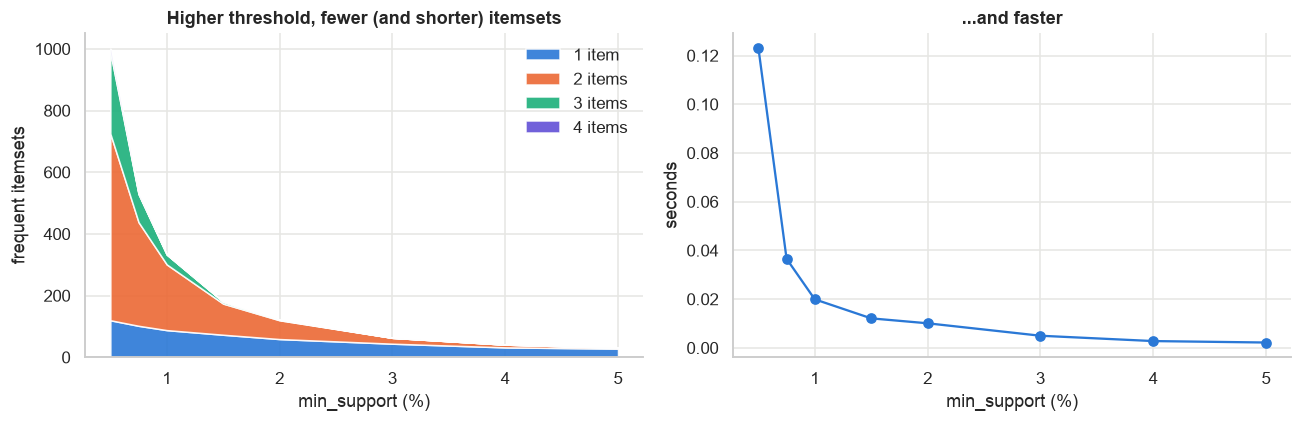

,min_support,itemsets,1-item,2-item,3-item,4-item,seconds
0,0.0050,1001,120,605,264,12,0.123144
1,0.0075,531,102,336,91,2,0.036535
2,0.0100,333,88,213,32,0,0.019901
3,0.0150,180,73,101,6,0,0.012090
4,0.0200,122,59,61,2,0,0.010066
5,0.0300,63,44,19,0,0,0.004957
6,0.0400,41,32,9,0,0,0.002767
7,0.0500,31,28,3,0,0,0.002171


In [11]:
grid = [0.005, 0.0075, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05]
rows = []
for ms in grid:
    t0 = time.time(); fi = apriori(onehot, min_support=ms, use_colnames=True, max_len=4)
    sz = fi["itemsets"].map(len)
    rows.append({"min_support": ms, "itemsets": len(fi), "1-item": (sz==1).sum(), "2-item": (sz==2).sum(),
                 "3-item": (sz==3).sum(), "4-item": (sz==4).sum(), "seconds": time.time()-t0})
sweep = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].stackplot(sweep["min_support"]*100, [sweep[c] for c in ["1-item","2-item","3-item","4-item"]],
                labels=["1 item","2 items","3 items","4 items"], colors=[BLUE, ORANGE, AQUA, VIOLET], alpha=.9)
ax[0].set(title="Higher threshold, fewer (and shorter) itemsets", xlabel="min_support (%)", ylabel="frequent itemsets"); ax[0].legend(frameon=False)
ax[1].plot(sweep["min_support"]*100, sweep["seconds"], "o-", color=BLUE)
ax[1].set(title="...and faster", xlabel="min_support (%)", ylabel="seconds")
plt.tight_layout(); plt.show()
sweep

**Trade-off.** The original project used 1.5%. Above about 3% there are barely any pairs, so there is nothing to recommend. Below 1% the output explodes with rare combinations that may be noise. We use **1%** (about 100 baskets) because it keeps useful pairs and triples. The original 1.5% is retained as the "conservative" setting for comparison.

size
1     88
2    213
3     32


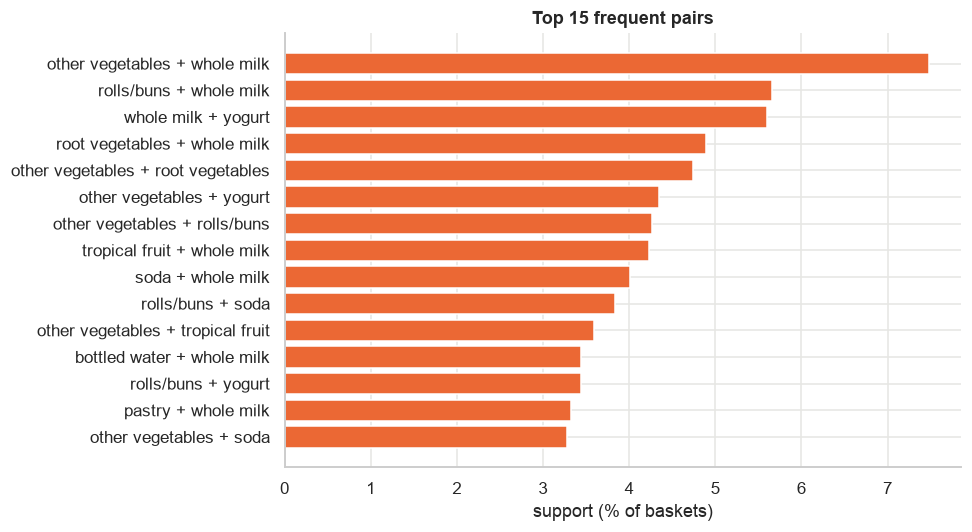

In [12]:
MIN_SUP = 0.01
freq = apriori(onehot, min_support=MIN_SUP, use_colnames=True, max_len=4)
freq["size"] = freq["itemsets"].map(len)
freq["itemset"] = freq["itemsets"].map(lambda s: " + ".join(sorted(s)))
print(freq["size"].value_counts().sort_index().to_string())
pairs = freq[freq["size"] == 2].sort_values("support", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
p = pairs.head(15)
ax.barh(p["itemset"][::-1], p["support"][::-1]*100, color=ORANGE)
ax.set(title="Top 15 frequent pairs", xlabel="support (% of baskets)")
plt.tight_layout(); plt.show()

## 4. From itemsets to rules

A rule `A -> B` ("people who buy A also buy B") is judged by:

| metric | formula | plain meaning |
|---|---|---|
| support | P(A and B) | how common the combination is |
| confidence | P(B given A) | how often B is bought when A is |
| **lift** | confidence / P(B) | how much A *raises* the chance of B vs. B's baseline. 1 = no effect |
| leverage | P(A and B) - P(A)P(B) | absolute gap from independence |
| conviction | (1 - P(B)) / (1 - confidence) | how wrong the rule would be if A and B were independent |

**Why lift matters.** `whole milk` is in 25% of all baskets, so almost *any* rule ending in milk has a high confidence. Confidence alone mostly rediscovers popular items. Lift removes that effect.

The original notebook filtered at `confidence >= 0.015`. That keeps almost every rule, so it filters nothing. We use sensible thresholds instead.

In [13]:
rules = association_rules(freq, metric="confidence", min_threshold=0.2)
rules = rules[rules["lift"] > 1.0].copy()
rules["antecedent"] = rules["antecedents"].map(lambda s: " + ".join(sorted(s)))
rules["consequent"] = rules["consequents"].map(lambda s: " + ".join(sorted(s)))
rules["rule"] = rules["antecedent"] + "  ->  " + rules["consequent"]
print(f"{len(rules)} rules with confidence >= 20% and lift > 1")
cols = ["rule", "support", "confidence", "lift", "leverage", "conviction"]
rules.sort_values("lift", ascending=False)[cols].head(12).round(3).reset_index(drop=True)

231 rules with confidence >= 20% and lift > 1


,rule,support,confidence,lift,leverage,conviction
0,citrus fruit + other vegetables -> root vege...,0.010,0.359,3.295,0.007,1.390
1,other vegetables + yogurt -> whipped/sour cream,0.010,0.234,3.267,0.007,1.212
2,other vegetables + tropical fruit -> root ve...,0.012,0.343,3.145,0.008,1.356
3,beef -> root vegetables,0.017,0.331,3.040,0.012,1.333
4,citrus fruit + root vegetables -> other vege...,0.010,0.586,3.030,0.007,1.949
5,root vegetables + tropical fruit -> other ve...,0.012,0.585,3.021,0.008,1.941
6,other vegetables + whole milk -> root vegeta...,0.023,0.310,2.842,0.015,1.291
7,root vegetables -> other vegetables + whole ...,0.023,0.213,2.842,0.015,1.175
8,butter -> other vegetables + whole milk,0.011,0.207,2.771,0.007,1.167
9,curd + whole milk -> yogurt,0.010,0.385,2.761,0.006,1.400


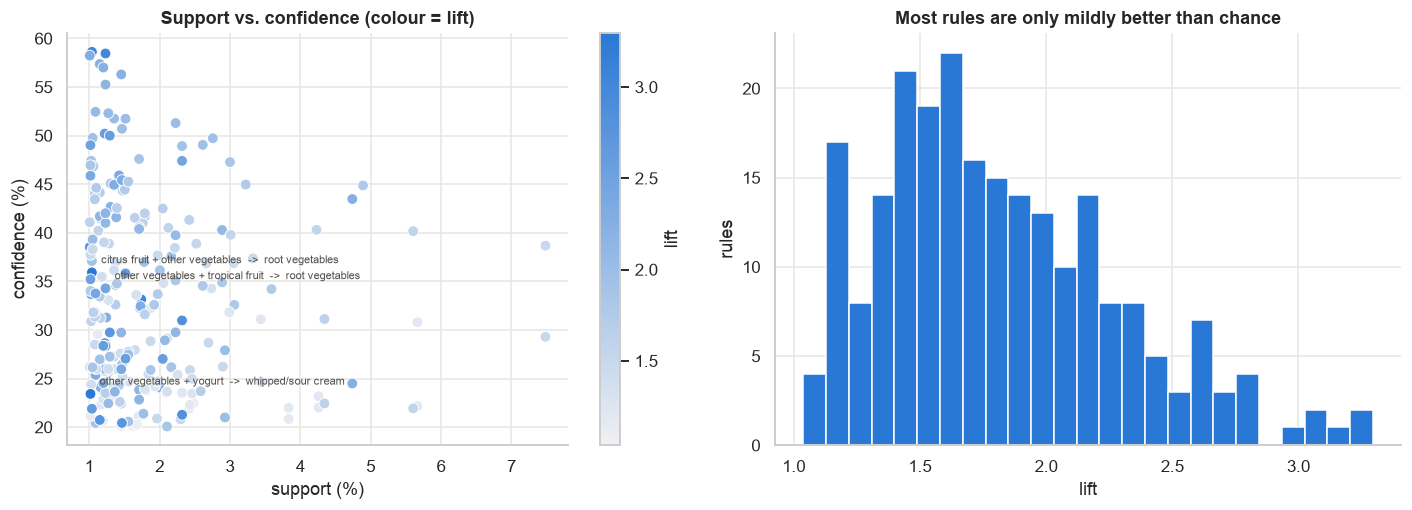

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sc = ax[0].scatter(rules["support"]*100, rules["confidence"]*100, c=rules["lift"], cmap=SEQ, s=50, edgecolor="white", linewidth=.6)
plt.colorbar(sc, ax=ax[0], label="lift")
ax[0].set(title="Support vs. confidence (colour = lift)", xlabel="support (%)", ylabel="confidence (%)")
best = rules.sort_values("lift", ascending=False).head(3)
for _, r in best.iterrows():
    ax[0].annotate(r["rule"], (r["support"]*100, r["confidence"]*100), (6, 6), textcoords="offset points", fontsize=7, color="#52514e")
ax[1].hist(rules["lift"], bins=25, color=BLUE)
ax[1].set(title="Most rules are only mildly better than chance", xlabel="lift", ylabel="rules")
plt.tight_layout(); plt.show()

**Reading the scatter.** Rules in the top-left (high confidence, low support) are reliable but rare. Rules to the right are common but weaker. The dark points (high lift) are the genuinely informative ones. Note that the *most frequent* rules are not the *most interesting* ones.

### 4.1 The rule network

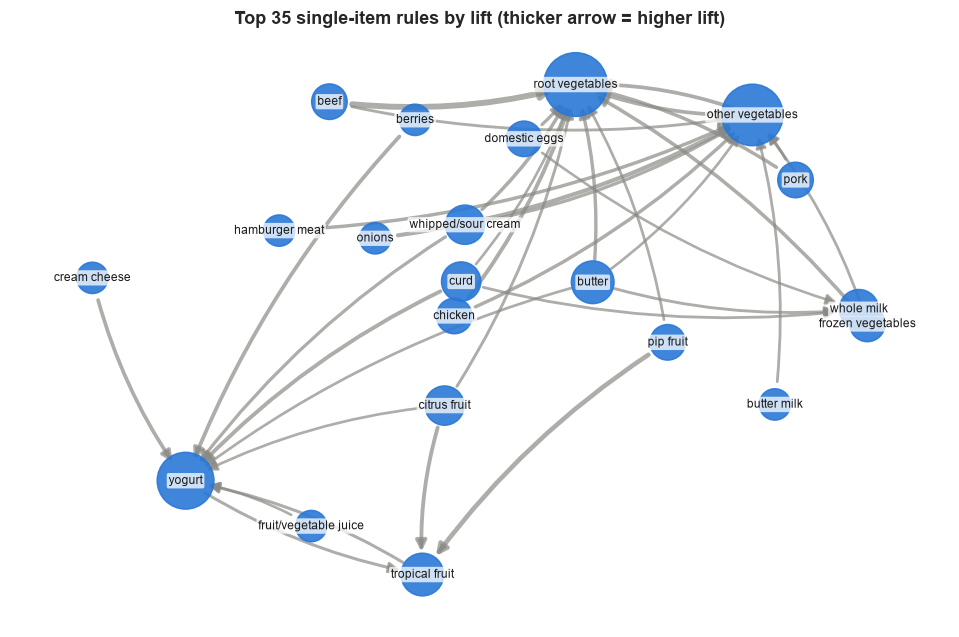

In [15]:
r1 = rules[(rules["antecedents"].map(len) == 1) & (rules["consequents"].map(len) == 1)].sort_values("lift", ascending=False).head(35)
G = nx.DiGraph()
for _, r in r1.iterrows():
    G.add_edge(r["antecedent"], r["consequent"], lift=r["lift"], conf=r["confidence"])
pos = nx.spring_layout(G, seed=7, k=1.1)
fig, ax = plt.subplots(figsize=(11, 7))
ws = [G[u][v]["lift"] for u, v in G.edges]
nx.draw_networkx_edges(G, pos, width=[(w-0.9)*1.8 for w in ws], edge_color=GRAY, alpha=.7, arrowsize=14,
                       connectionstyle="arc3,rad=0.1", node_size=900, ax=ax)
deg = dict(G.degree)
nx.draw_networkx_nodes(G, pos, node_size=[300+120*deg[n] for n in G], node_color=BLUE, alpha=.9, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8, ax=ax, bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=.75))
ax.set_title("Top 35 single-item rules by lift (thicker arrow = higher lift)"); ax.axis("off"); plt.show()

**Takeaway.** Fresh products dominate the strongest rules. `root vegetables`, `other vegetables`, `yogurt` and `tropical fruit` are the big nodes that many rules point to (node size = number of connections). Meat and dairy items (`beef`, `pork`, `chicken`, `curd`, `butter`) mostly point *into* produce.

## 5. The recommender

The original project used a function that returned **every item in any frequent itemset containing the chosen items, in no particular order**. It works, but it cannot say *which* suggestion is best. Here are both versions side by side.

In [16]:
# --- version 1: the original find() (unranked) ---
def find(chosen, freq_itemsets):
    out = []
    for s in freq_itemsets["itemsets"]:
        if set(chosen).issubset(s):
            out.extend(s)
    return sorted(set(x for x in out if x not in chosen))

# --- version 2: ranked by rule confidence ---
def recommend(chosen, rules_df, k=5):
    chosen = frozenset(chosen)
    hit = rules_df[rules_df["antecedents"].map(lambda a: a <= chosen)]
    scores = {}
    for _, r in hit.iterrows():
        for c in r["consequents"]:
            if c not in chosen:
                scores[c] = max(scores.get(c, 0), r["confidence"])
    return sorted(scores, key=scores.get, reverse=True)[:k]

for basket in (["whole milk"], ["whole milk", "root vegetables"], ["yogurt", "tropical fruit"]):
    print(f"basket: {basket}")
    print("   find()      :", find(basket, freq[freq['size'] > 1]))
    print("   recommend() :", recommend(basket, rules))

basket: ['whole milk']
   find()      : ['beef', 'berries', 'bottled beer', 'bottled water', 'brown bread', 'butter', 'butter milk', 'chicken', 'chocolate', 'citrus fruit', 'coffee', 'cream cheese', 'curd', 'dessert', 'domestic eggs', 'frankfurter', 'frozen vegetables', 'fruit/vegetable juice', 'ham', 'hamburger meat', 'hard cheese', 'hygiene articles', 'long life bakery product', 'margarine', 'napkins', 'newspapers', 'oil', 'onions', 'other vegetables', 'pastry', 'pip fruit', 'pork', 'rolls/buns', 'root vegetables', 'salty snack', 'sausage', 'shopping bags', 'sliced cheese', 'soda', 'sugar', 'tropical fruit', 'waffles', 'whipped/sour cream', 'white bread', 'yogurt']
   recommend() : ['other vegetables', 'rolls/buns', 'yogurt']
basket: ['whole milk', 'root vegetables']
   find()      : ['other vegetables', 'rolls/buns', 'tropical fruit', 'yogurt']
   recommend() : ['other vegetables', 'yogurt', 'rolls/buns', 'tropical fruit']
basket: ['yogurt', 'tropical fruit']
   find()      : ['othe

`recommend()` returns a short ranked list instead of an unordered pile. We rank by confidence; section 6 tests whether that (or lift) is actually the better score.

## 6. Evaluation: does it beat just recommending the best-sellers?

Eyeballing examples is not evaluation. We test it properly:

1. Split baskets 80/20 into train and test. **Mine rules only on train.**
2. For each test basket with 2+ items, **hide one item at random** and give the recommender the rest.
3. **Hit rate @ k**: did the hidden item appear in the top-k suggestions?
4. Compare against a **popularity baseline** (always suggest the best-sellers not already in the basket).

train baskets: 7,868  test baskets (2+ items): 1,538  rules used: 2,312


share of test baskets where at least one rule fired: 97.1%


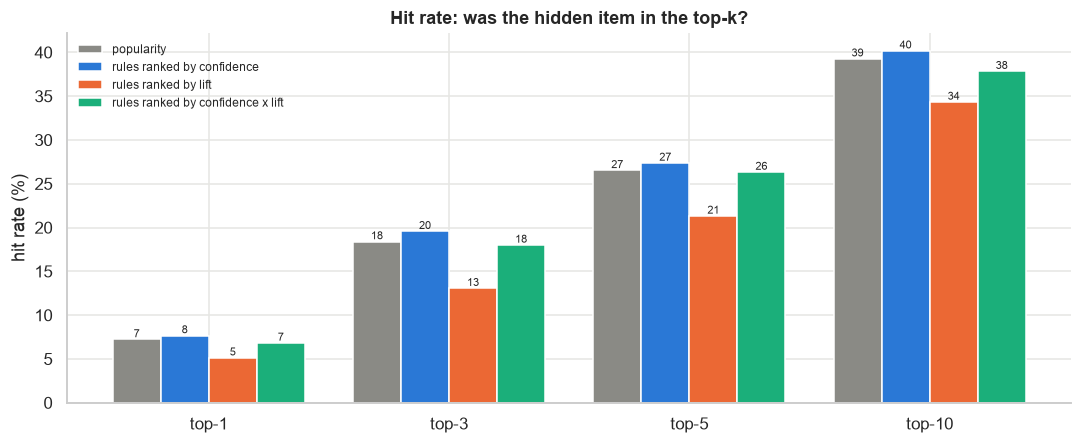

,popularity,rules ranked by confidence,rules ranked by lift,rules ranked by confidence x lift
k,,,,
1,0.072,0.077,0.051,0.068
3,0.184,0.196,0.131,0.180
5,0.265,0.274,0.213,0.263
10,0.393,0.402,0.343,0.378


In [17]:
perm = RNG.permutation(len(baskets)); cut = int(.8*len(baskets))
train = [baskets[i] for i in perm[:cut]]; test = [baskets[i] for i in perm[cut:] if len(set(baskets[i])) >= 2]
oh_tr = pd.DataFrame(te.fit(train).transform(train), columns=te.columns_)
fi_tr = apriori(oh_tr, min_support=0.005, use_colnames=True, max_len=3)   # lower threshold so more baskets are covered
rl_tr = association_rules(fi_tr, metric="confidence", min_threshold=0.05)
rl_tr = rl_tr[rl_tr["lift"] > 1.0]
pop_order = [i for i, _ in Counter(i for b in train for i in b).most_common()]
print(f"train baskets: {len(train):,}  test baskets (2+ items): {len(test):,}  rules used: {len(rl_tr):,}")

# index rules by antecedent for speed
from collections import defaultdict
SCORES = {"confidence": lambda c, l: c, "lift": lambda c, l: l, "confidence x lift": lambda c, l: c*l}
by_ante = {name: defaultdict(list) for name in SCORES}
for a, c, conf, lf in zip(rl_tr["antecedents"], rl_tr["consequents"], rl_tr["confidence"], rl_tr["lift"]):
    for name, f in SCORES.items(): by_ante[name][a].append((c, f(conf, lf)))

def rec_fast(chosen, k, score="confidence"):
    chosen = frozenset(chosen); sc = {}
    for n in (1, 2):
        for a in combinations(sorted(chosen), n):
            for cons, s in by_ante[score].get(frozenset(a), []):
                for x in cons:
                    if x not in chosen: sc[x] = max(sc.get(x, 0), s)
    ranked = sorted(sc, key=sc.get, reverse=True)
    # fill remaining slots with best-sellers so both methods always return k items
    ranked += [p for p in pop_order if p not in chosen and p not in ranked]
    return ranked[:k], len(sc) > 0

def pop_fast(chosen, k): return [p for p in pop_order if p not in chosen][:k]

Ks = [1, 3, 5, 10]; methods = ["popularity"] + [f"rules ranked by {n}" for n in SCORES]
res = {m: {k: 0 for k in Ks} for m in methods}; covered = 0
for b in test:
    b = list(dict.fromkeys(b)); hid = b[RNG.integers(len(b))]; rest = [x for x in b if x != hid]
    p_list = pop_fast(rest, max(Ks))
    for k in Ks: res["popularity"][k] += hid in p_list[:k]
    for n in SCORES:
        r_list, has_rule = rec_fast(rest, max(Ks), n)
        for k in Ks: res[f"rules ranked by {n}"][k] += hid in r_list[:k]
    covered += has_rule
hr = pd.DataFrame(res) / len(test); hr.index.name = "k"
print(f"share of test baskets where at least one rule fired: {covered/len(test):.1%}")
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(Ks)); w = .2; cols = [GRAY, BLUE, ORANGE, AQUA]
for m, (name, col) in enumerate(zip(methods, cols)):
    bars = ax.bar(x + (m-1.5)*w, hr[name]*100, w, label=name, color=col)
    ax.bar_label(bars, fmt="%.0f", fontsize=7)
ax.set_xticks(x, [f"top-{k}" for k in Ks]); ax.set(title="Hit rate: was the hidden item in the top-k?", ylabel="hit rate (%)"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show(); hr.round(3)

**Honest reading.**
- Ranked by **confidence**, the rules are **on par with the popularity baseline**: the gap is about a point or less, which is within sampling noise with only ~1,500 test baskets (roughly +/-1 point). They do not clearly beat it.
- Ranking by **lift** is clearly *worse* for prediction: high-lift rules point to rare items that are interesting but seldom the item actually missing from a basket.
- So lift is the right tool for *discovering* surprising associations (section 4), and confidence is the better tool for *predicting* the next item.
- The reason: this is a small, popularity-dominated catalogue of 169 broad categories (`whole milk`, `rolls/buns`...), with no information about *who* is shopping. Best-sellers are hard to beat.

What rules do offer is **explainability** ("because you bought X and Y") and a transparent model, which a popularity list cannot give. But a high-quality recommender needs more signal, which is the subject of the companion notebook.

## 7. Limitations and what comes next

- **No user personalisation.** A basket is anonymous, with no history and no taste profile.
- **Popularity bias.** Rare items almost never appear in rules (see the long tail in 2.3).
- **Static.** The rules are not updated as tastes change, and they ignore the order in which items were added.
- **Cold start.** A new product has no rules until it sells enough.

Modern recommenders address these with learned embeddings, user histories and sequence models. The companion notebook, **`02-modern-recommenders-movielens.ipynb`**, shows how, on a dataset with real users.

---
*Data: Hahsler et al. (2006), via the `arules` package and Kaggle. Method: Agrawal & Srikant (1994), "Fast algorithms for mining association rules". Library: [mlxtend](https://rasbt.github.io/mlxtend/).*